# End-to-end: clustering

This notebook runs one clustering job from the question to the report: which groups of similar wines are there, judged only from a lab analysis? It uses the same seven steps as every end-to-end notebook of the course, so you can compare the kinds of problems side by side.

*Session 11, end-to-end notebook. Course material, licence CC BY 4.0.*

## 1 The problem

A wine merchant buys 178 wines from one region of Italy. The lab has measured 13 values for each wine: alcohol, acidity, colour, phenols and so on. The merchant wants to **group similar wines** to plan tasting evenings and shelf sections, but has no list that says which wine belongs to which group.

There is no target to predict: the groups must come from the measurements themselves. This is a **clustering** problem. A clustering always returns groups, so the questions are how many groups there are, whether they are clear and stable, and what they mean to the merchant.

## 2 Load the data

We import the libraries that every step uses. Each later step imports the scikit-learn parts it needs where it uses them.

In [1]:
# matplotlib draws the figures, numpy holds arrays, pandas holds tables
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
# seaborn draws the heatmap of the cluster profiles and sets one clean style for all figures
import seaborn as sns
# load_wine reads a data set that ships with scikit-learn
from sklearn.datasets import load_wine

# whitegrid: white background with light grid lines; font_scale=1.1 makes all text a little larger
sns.set_theme(style="whitegrid", font_scale=1.1)

The wine data (Forina and colleagues, University of Genoa, 1988) ship with scikit-learn, so no download is needed. `load_wine(as_frame=True)` returns the measurements as a DataFrame. The data also record the grape variety of each wine (`cultivar`, three kinds). A merchant would not have it, so we keep it aside. The clustering never sees it; in step 7 we use it only as an outside check of the result.

In [2]:
# as_frame=True returns the 13 measurements as a DataFrame
wine_data = load_wine(as_frame=True)
# wines: one row per wine, one column per measurement
wines = wine_data.data
# cultivar: the grape variety, 0, 1 or 2; kept aside and never used to build the clusters
cultivar = wine_data.target.rename("cultivar")
# shape is (number of wines, number of measurements)
print(wines.shape)

(178, 13)


Each row is one wine. The table explains the 13 columns for readers who are not wine chemists; the clustering uses all of them. **Phenols** are the compounds that give red wine its colour, bitterness and dry feel in the mouth. The data documentation does not give a unit for every column; the table says so where it is missing. The grape variety `cultivar` (0, 1 or 2) is not one of the 13 columns: it is kept aside, as explained above.

| Column | Meaning | Unit |
|---|---|---|
| `alcohol` | alcohol content | % by volume |
| `malic_acid` | malic acid, a sour acid also found in apples | g per litre |
| `ash` | ash: the minerals left after the wine is burnt | g per litre |
| `alcalinity_of_ash` | how alkaline (the opposite of acidic) the ash is | not given |
| `magnesium` | magnesium, a mineral | mg per litre |
| `total_phenols` | all phenols together | not given |
| `flavanoids` | flavanoids, the largest group of phenols | not given |
| `nonflavanoid_phenols` | the phenols that are not flavanoids | not given |
| `proanthocyanins` | proanthocyanins, phenols that make the wine taste dry (tannins) | not given |
| `color_intensity` | how deep the colour is, from the light the wine absorbs | no unit (an index) |
| `hue` | the shade of the colour, a ratio of the light absorbed at two colours | no unit (a ratio) |
| `od280/od315_of_diluted_wines` | ratio of the ultraviolet light absorbed at two wavelengths, a lab measure of phenols | no unit (a ratio) |
| `proline` | proline, an amino acid (a building block of proteins) | mg per litre |


## 3 Look at the data

`describe()` computes summary numbers of every column; `.T` turns the result so that each measurement is one row. We keep the mean, the standard deviation (`std`), the smallest and the largest value. Look at the scales.

In [3]:
# Summary of all 13 columns, one row per column, rounded to two decimals
wines.describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


**What do you see?** The columns live on very different scales. `proline` (an amino acid, in mg per litre) runs from 278 to 1,680, `magnesium` from 70 to 162, while `hue` stays between 0.48 and 1.71. Clustering works with distances, so without scaling, a difference of 100 in `proline` would outweigh any difference in `hue`, and `proline` alone would decide which wines are "close".

A scatter plot of two columns shows whether groups are visible by eye. We take `alcohol` and `flavanoids`.

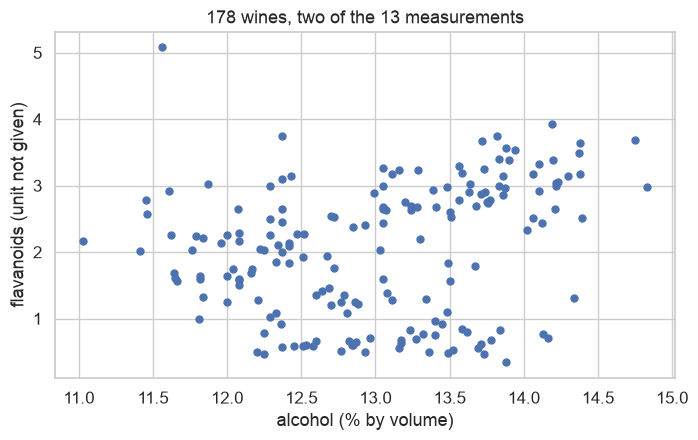

In [4]:
# One dot per wine: alcohol on the x-axis, flavanoids on the y-axis; s=15 sets the dot size
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(wines["alcohol"], wines["flavanoids"], s=25)
ax.set_xlabel("alcohol (% by volume)")
ax.set_ylabel("flavanoids (unit not given)")
ax.set_title("178 wines, two of the 13 measurements")
plt.show()

**What do you see?** Two or three clouds can be guessed, but they touch. The other 11 columns may separate them better, so the clustering uses all 13.

## 4 Split the data

There is no target, so there is nothing to hold out and no test error to compute. We cluster all 178 wines. Instead of a test score, we ask two questions. Are the groups well separated? The **silhouette score** answers this in step 6, with a 95% interval in step 7. Do the groups come back when the wines change a little? A **stability check** in section 6.5 clusters resampled wines and compares the groups.

## 5 Process the data

All 13 columns are numbers, so one step is enough and we need no `ColumnTransformer`. Clustering groups wines by their distance, and in step 3 the columns had very different scales. `StandardScaler` gives each column a mean of 0 and a standard deviation of 1, so every measurement counts the same in the distance. The plot below shows `proline` (hundreds to thousands) and `hue` (around 1) before and after scaling.

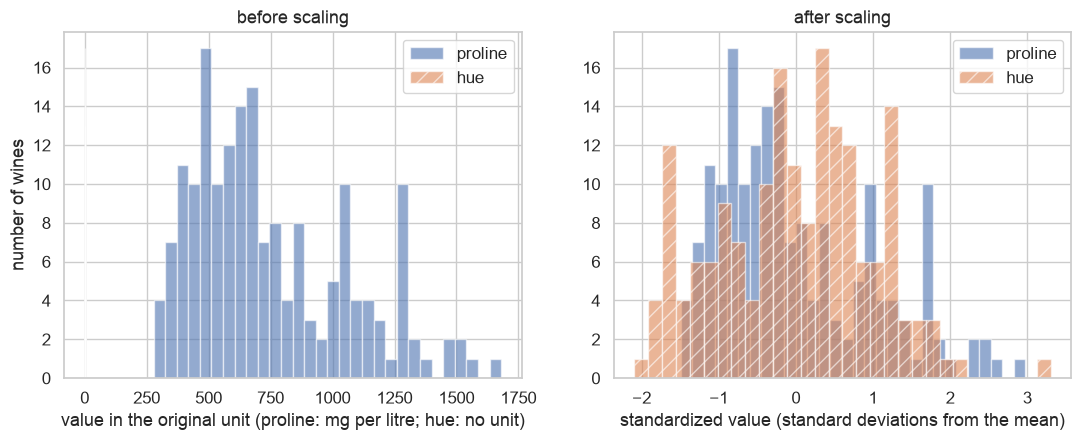

In [5]:
from sklearn.preprocessing import StandardScaler

# fit_transform learns the mean and standard deviation of each column and returns the scaled array;
# pd.DataFrame puts it back into a table with the column names, so we can select columns by name
scaled_wines = pd.DataFrame(StandardScaler().fit_transform(wines), columns=wines.columns)

# Left: the raw values of two columns; right: the same two columns after scaling
fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(13, 4.5))
ax_before.hist(wines["proline"], bins=30, alpha=0.6, label="proline")
ax_before.hist(wines["hue"], bins=30, alpha=0.6, hatch="//", label="hue")
ax_before.set_title("before scaling")
ax_before.set_xlabel("value in the original unit (proline: mg per litre; hue: no unit)")
ax_before.set_ylabel("number of wines")
ax_before.legend()

ax_after.hist(scaled_wines["proline"], bins=30, alpha=0.6, label="proline")
ax_after.hist(scaled_wines["hue"], bins=30, alpha=0.6, hatch="//", label="hue")
ax_after.set_title("after scaling")
ax_after.set_xlabel("standardized value (standard deviations from the mean)")
ax_after.legend()
plt.show()

**What do you see?** Before scaling, `proline` spreads from about 280 to 1,680. All values of `hue` lie between 0.48 and 1.71, so on the same axis its histogram is a thin bar at 0 that you can hardly see. After scaling, both columns are centred at 0 with a standard deviation of 1, and they overlap on one axis. The shape of each distribution stays the same: scaling moves and stretches the values, but it does not change their order.

A table checks all 13 columns at once: the mean and the standard deviation of every scaled column.

In [6]:
# Mean and standard deviation of every scaled column, one row per column.
# std(ddof=0) divides by n, as StandardScaler does (pandas divides by n - 1 by default);
# replace(-0.0, 0.0) shows a tiny negative mean, rounded to -0.00, as 0.00
scaling_check = pd.DataFrame({"mean": scaled_wines.mean(), "standard deviation": scaled_wines.std(ddof=0)})
scaling_check.round(2).replace(-0.0, 0.0)

,mean,standard deviation
alcohol,0.0,1.0
malic_acid,0.0,1.0
ash,0.0,1.0
alcalinity_of_ash,0.0,1.0
magnesium,0.0,1.0
total_phenols,0.0,1.0
flavanoids,0.0,1.0
nonflavanoid_phenols,0.0,1.0
proanthocyanins,0.0,1.0
color_intensity,0.0,1.0


**What do you see?** Every one of the 13 columns now has a mean of 0 and a standard deviation of 1, to two decimals. The table shows them as 0.0 and 1.0.

## 6 Run the pipeline

We start with the most common method, k-means, with a first guess of k = 8, and score it. Then we tune its one important hyperparameter, the number of clusters k, by trying k = 2 to 8. We turn the chosen clusters into names and actions for the merchant. Then we compare a second method, agglomerative clustering, on the same scores. The five decisions of the two methods:

| Decision | k-means | Agglomerative clustering (Ward) |
|---|---|---|
| Data | the 13 scaled measurements X of all wines; no target y | the same |
| Model | k cluster centres; every wine belongs to its nearest centre | a tree of merges: every wine starts as its own cluster, and the tree is cut at k clusters |
| Loss function | inertia: the sum of squared distances from each wine to the centre of its cluster | the same sum, kept small one merge at a time: Ward merges the two clusters that raise it the least |
| Optimizer | Lloyd's algorithm: assign each wine to the nearest centre, move each centre to the mean of its wines, repeat; 10 starts (`n_init=10`) | no iterations: the greedy merges are computed once, from the bottom up |
| Evaluation | silhouette score, inertia, the clusters on a 2D map, stability, and whether the groups make sense to the merchant | the same |

Every clustering is scored in the same way, with three measures. Each cell below computes them in plain code:

- **Silhouette score** (`silhouette_score(X, cluster_labels)`): for each wine, `a` is its mean distance to the other wines of its cluster and `b` its mean distance to the wines of the nearest other cluster. Its silhouette is (b − a) / max(a, b), from −1 to 1. The score is the mean over all wines: near 1, clear groups; near 0, groups that touch; below 0, many wines sit closer to another group. Higher is better.
- **Inertia**: how tightly the wines sit around the centre (the mean) of their own cluster. For each wine, take its distance to the centre of its cluster, square it, and add up the 178 squared distances. A small example with one measurement: a cluster of three wines with the values 1, 2 and 6 has the centre 3, so its inertia is (1 − 3)² + (2 − 3)² + (6 − 3)² = 4 + 1 + 9 = 14. Small inertia means compact clusters. The number has no good or bad level of its own, because it depends on the data and on k. It also always falls as k grows (down to 0 when every wine is its own cluster), so we use it only to compare different k on the same data in 6.2, and never to pick the largest k. A fitted k-means stores it as `inertia_`.
- **A 2D picture of the clusters**, to look at them. The next cells explain it.

**Why a 2D picture, and what PCA does.** As in the slides (Part 3, *A map with PCA*): each wine has 13 numbers, but a plot has only two axes. PCA (principal component analysis) finds new axes for the same wines. The first new axis points in the direction in which the wines differ most. The second points in the direction of the next largest difference, at a right angle to the first. Each new axis is a mixture of the 13 scaled columns. We keep only the first two, the **principal components**, so every wine gets two numbers, and these are the x and y of the picture. The goal of PCA is to squeeze 13 columns into 2 and lose as little of the spread as possible.

**PCA is only for looking: it plays no part in the clustering.** k-means and agglomerative clustering always work on all 13 scaled columns. We draw the clusters onto the PCA picture afterwards, to see the result with our own eyes. The picture does not change which wine goes to which cluster.


In [7]:
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# PCA with two components; fit_transform returns an array with two numbers per wine
pca_2d = PCA(n_components=2)
wines_pca_2d = pca_2d.fit_transform(scaled_wines)
# Before: 178 wines × 13 columns; after: 178 wines × 2 columns
print("scaled_wines:", scaled_wines.shape, "→ wines_pca_2d:", wines_pca_2d.shape)
# explained_variance_ratio_ is the share of the total spread that each component keeps
print(f"the 2D map keeps {pca_2d.explained_variance_ratio_.sum():.0%} of the spread of the 13 scaled columns")

# The two new columns as a table: column 0 becomes the x-axis of the map, column 1 the y-axis
wines_pca_2d_table = pd.DataFrame(wines_pca_2d, columns=["x: first principal component", "y: second principal component"])
wines_pca_2d_table.index.name = "wine"
wines_pca_2d_table

scaled_wines: (178, 13) → wines_pca_2d: (178, 2)
the 2D map keeps 55% of the spread of the 13 scaled columns


,x: first principal component,y: second principal component
wine,,
0,3.316751,1.443463
1,2.209465,-0.333393
2,2.516740,1.031151
3,3.757066,2.756372
4,1.008908,0.869831
...,...,...
173,-3.370524,2.216289
174,-2.601956,1.757229
175,-2.677839,2.760899


Each row of `wines_pca_2d` (the wines in 2 PCA columns) is one wine, described by 2 numbers instead of 13. To draw it, the first column is the x-coordinate and the second column the y-coordinate of the wine's dot. `wines_pca_2d[:, 0]` means "all rows, column 0" and `wines_pca_2d[:, 1]` "all rows, column 1". The map has no unit: the components are mixtures of scaled columns.

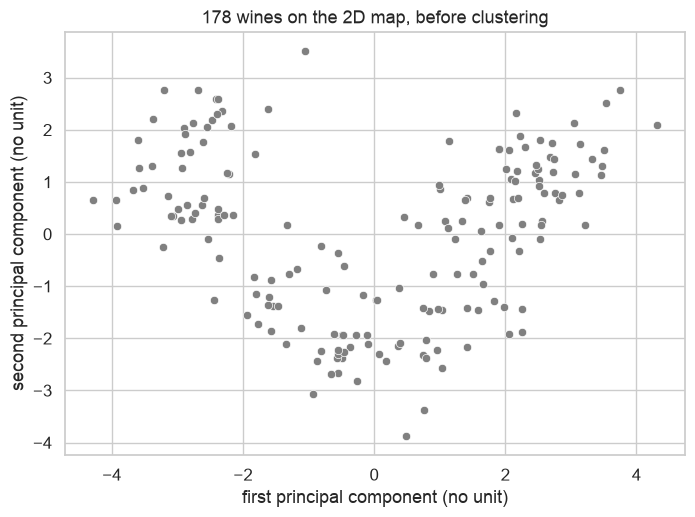

In [8]:
# One dot per wine at (first principal component, second principal component); no clusters yet
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(x=wines_pca_2d[:, 0], y=wines_pca_2d[:, 1], color="grey", ax=ax)
ax.set_title("178 wines on the 2D map, before clustering")
ax.set_xlabel("first principal component (no unit)")
ax.set_ylabel("second principal component (no unit)")
plt.show()

**What do you see?** Every dot is one row of the table above: wine 0, for example, sits at x = 3.3 and y = 1.4, on the right. The dots form a curved band with three denser regions: upper left, bottom and upper right. The eye already suggests groups, before any clustering. The map keeps 55% of the spread of the 13 columns, so two wines that look close here can still differ in the directions the map leaves out. In 6.1 we draw these same dots again and only add colour: `hue=` gives each wine the colour of its cluster.

### 6.1 A first k-means with k = 8

k-means needs the number of clusters k before it runs, and we always write it out: `KMeans(n_clusters=8)`. If `n_clusters` is left out, scikit-learn quietly uses 8, and we do not rely on a hidden setting. We start with k = 8 on purpose: it is more clusters than the three clouds we guessed from the map, so we can see what too many clusters look like and compare with better choices of k in 6.2. A `Pipeline` chains the scaling of step 5 and k-means, so `fit_predict` scales the wines, fits the centres and returns the cluster number of every wine. `n_init=10` runs k-means from 10 different starts and keeps the best; `random_state=0` makes the starts the same every time.

In [9]:
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline

# A Pipeline runs its steps in order: first scale the 13 columns, then k-means.
# n_clusters=8 is our own choice of k: a deliberately large first try
kmeans_8_pipeline = Pipeline([("scaling", StandardScaler()),
                                    ("kmeans", KMeans(n_init=10, random_state=0))])
# fit_predict fits both steps and returns one cluster number (0 to 7) per wine
kmeans_8_cluster = kmeans_8_pipeline.fit_predict(wines)

# What fit_predict returns: a NumPy array with one cluster number per wine, all 178 of them
print(kmeans_8_cluster)
print("shape:", kmeans_8_cluster.shape)

[1 1 1 1 3 1 1 1 1 1 1 1 1 1 1 1 3 3 1 1 1 3 1 3 3 3 1 1 3 1 3 1 3 3 3 3 3
 3 5 1 1 6 1 6 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 5 0 0 5 5 0 3 5 5 0 5 0 3 0 3
 5 5 5 0 5 6 5 5 0 4 6 5 0 0 0 0 0 0 0 6 5 3 2 5 5 6 5 5 6 5 5 0 5 0 5 6 6
 6 0 0 0 0 5 5 4 6 6 3 6 6 6 6 6 0 6 6 2 2 2 2 0 4 4 4 4 4 4 4 4 4 2 4 4 4
 7 2 2 2 2 7 7 4 7 4 7 7 4 4 4 4 7 4 7 7 7 2 4 7 7 4 7 7 7 7]
shape: (178,)


**What does `fit_predict` return?** In regression the prediction is a number, such as 189 bikes. In classification it is one of the known classes, such as "malignant". In clustering there are no known classes. The prediction is a **cluster number** for every wine: 0, 1, …, 7. The number is only a name for a group. Cluster 3 is not "more" than cluster 1, and the numbers can change from one run to another.

To see the result as a table, we add the cluster numbers to a copy of the wines as a new first column. `insert(0, "cluster", values)` puts a column at position 0, the left end of the table.

In [10]:
# One row per wine: its cluster number first, then its 13 measurements
# copy() keeps the original table wines unchanged; insert(0, ...) adds the column at position 0, the left end
wines_with_cluster = wines.copy()
wines_with_cluster.insert(0, "cluster", kmeans_8_cluster)
wines_with_cluster

,cluster,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,1,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,1,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,3,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,4,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0
174,7,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0
175,7,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0
176,7,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0


What did k-means learn to make this prediction? Its model is one **centre** per cluster: the mean of the wines in the cluster, in the scaled units of step 5. `cluster_centers_` holds them as an array with one row per cluster and one column per measurement. A wine gets the number of the centre it is closest to.

In [11]:
# named_steps["kmeans"] is the fitted k-means step of the pipeline
fitted_kmeans = kmeans_8_pipeline.named_steps["kmeans"]
# One row per cluster, one column per measurement; values are in standard deviations from the mean
kmeans_8_centres = pd.DataFrame(fitted_kmeans.cluster_centers_, columns=wines.columns).round(2)
kmeans_8_centres.index.name = "cluster"
kmeans_8_centres

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
cluster,,,,,,,,,,,,,
0,-1.01,-0.63,0.05,0.49,-0.64,-0.62,-0.42,1.03,-0.54,-0.84,0.59,-0.24,-0.68
1,1.09,-0.34,0.10,-1.02,0.45,1.01,1.06,-0.73,0.69,0.38,0.39,0.85,1.35
2,-0.20,0.55,0.48,0.74,0.99,-1.19,-0.84,-0.97,-0.80,0.77,-1.23,-1.51,-0.53
3,0.33,-0.44,1.12,0.37,0.85,0.68,0.84,-0.21,0.48,-0.24,0.81,0.63,0.57
4,0.05,1.35,0.14,0.49,-0.44,-1.05,-1.38,1.21,-1.10,0.25,-0.97,-1.10,-0.42
5,-0.76,-0.87,-1.44,-0.47,-0.38,0.04,0.06,-0.66,-0.02,-0.76,0.72,0.36,-0.64
6,-0.88,0.67,-0.23,0.34,-0.56,0.43,0.47,-0.25,0.67,-0.99,-0.26,0.65,-0.81
7,0.56,0.57,0.25,0.58,-0.08,-0.81,-1.25,0.92,-0.21,2.00,-1.43,-1.35,-0.27


**How to read the table of centres.** Every value is in standard deviations from the average wine: 0 means average, +1 means one standard deviation above the average wine, −1 one below. Take cluster 1: `proline` is +1.35 and `alcohol` is +1.09. The average wine has 746.9 mg of proline per litre with a standard deviation of 314.0, so the wines of cluster 1 have about 746.9 + 1.35 × 314.0 ≈ 1,171 mg per litre, far above average. In the same way, alcohol is about 13.00 + 1.09 × 0.81 ≈ 13.9 % (the average wine has 13.00 % with a standard deviation of 0.81). Cluster 0 is the opposite: `alcohol` −1.01 (about 12.2 %) and `color_intensity` −0.84, so pale wines with little alcohol. Read one row of the table as the typical wine of its cluster.

Now we judge the eight clusters with the two scores of step 6 and draw them on the 2D map.

One line draws a map of clusters: `sns.scatterplot(x=..., y=..., hue=cluster_labels)`. `x` and `y` are the two columns of the map, and `hue` gives every cluster number its own colour and adds a legend. Every cluster map in this notebook uses this line.

k-means, k = 8: silhouette 0.158, inertia 945, wines per cluster [23, 41, 11, 20, 23, 25, 19, 16]


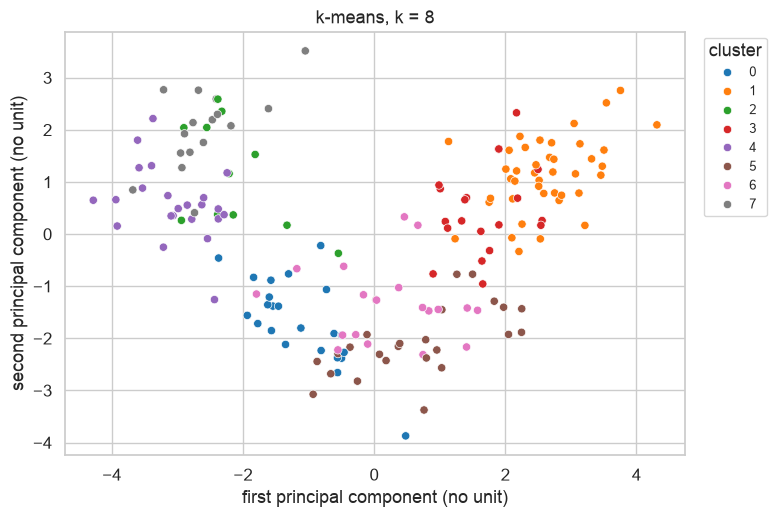

In [12]:
# The silhouette score compares each wine's own cluster with the nearest other cluster
kmeans_8_silhouette = silhouette_score(scaled_wines, kmeans_8_cluster)
# named_steps["kmeans"] is the fitted k-means step; inertia_ is its sum of squared distances
kmeans_8_inertia = kmeans_8_pipeline.named_steps["kmeans"].inertia_
# np.bincount counts the wines with cluster number 0, 1, 2, ...
kmeans_8_cluster_sizes = np.bincount(kmeans_8_cluster).tolist()
print(f"k-means, k = 8: silhouette {kmeans_8_silhouette:.3f}, inertia {kmeans_8_inertia:.0f}, "
      f"wines per cluster {kmeans_8_cluster_sizes}")

# The eight clusters on the 2D map in one call: x and y are the two map columns,
# hue gives every cluster number its own colour, palette="tab10" chooses ten clearly different colours
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(x=wines_pca_2d[:, 0], y=wines_pca_2d[:, 1], hue=kmeans_8_cluster, palette="tab10", ax=ax)
ax.set_title("k-means, k = 8")
ax.set_xlabel("first principal component (no unit)")
ax.set_ylabel("second principal component (no unit)")
# bbox_to_anchor puts the legend outside the plot, to the right, so it hides no wine
ax.legend(title="cluster", fontsize=9, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**What do you see?** With k = 8, the silhouette score is 0.158, the inertia is 945, and the clusters hold from 11 to 41 wines. How to read these three numbers:
- **Silhouette 0.158** is close to 0: many wines sit almost as close to another cluster as to their own, so the groups touch. A common rule of thumb (Kaufman and Rousseeuw, 1990) is that above 0.5 the groups are clear and below 0.25 there is hardly any structure. This is a weak result; k = 3 will reach 0.285.
- **Inertia 945** has no good or bad level on its own. It becomes useful next to the inertia of other k: in 6.2 it is 1,659 for k = 2 and 1,278 for k = 3. It is low here only because eight centres always fit the wines more closely than three.
- **11 to 41 wines per cluster**: eight groups for 178 wines, and the smallest holds 11.

On the map, several clusters share one cloud: clusters 2, 4 and 7 overlap at the upper left, and clusters 0, 5 and 6 share the lower part. Eight groups cut clouds that look like one group into pieces, and eight shelf sections are more than the merchant asked for. k = 8 is not a good choice for these data, so we tune k in 6.2.

### 6.2 Tune the number of clusters

k is a **hyperparameter**: we choose it, the method does not learn it. `GridSearchCV` needs a score on held-out rows, which clustering does not have, so we write the search as a loop: one k-means for each k from 2 to 8. For each k we keep the cluster labels, the inertia (`inertia_` of the fitted k-means step) and the silhouette score.

In [13]:
# One fitted k-means per k; the labels of each are kept for the plots and for step 7,
# the fitted pipelines for using the chosen one on new wines in 7.3
kmeans_cluster_by_k = {}
kmeans_pipeline_by_k = {}
kmeans_search_rows = []
for number_of_clusters in range(2, 9):
    kmeans_pipeline = Pipeline([("scaling", StandardScaler()),
                                ("kmeans", KMeans(n_clusters=number_of_clusters, n_init=10, random_state=0))])
    kmeans_cluster_by_k[number_of_clusters] = kmeans_pipeline.fit_predict(wines)
    kmeans_pipeline_by_k[number_of_clusters] = kmeans_pipeline
    # named_steps["kmeans"] is the fitted k-means step; inertia_ is its loss
    kmeans_search_rows.append({
        "k": number_of_clusters,
        "inertia": kmeans_pipeline.named_steps["kmeans"].inertia_,
        "silhouette": silhouette_score(scaled_wines, kmeans_cluster_by_k[number_of_clusters]),
    })
kmeans_search = pd.DataFrame(kmeans_search_rows).set_index("k")
kmeans_search.round(3)

,inertia,silhouette
k,,
2,1659.008,0.268
3,1277.928,0.285
4,1180.738,0.246
5,1110.365,0.203
6,1044.470,0.196
7,995.995,0.139
8,944.559,0.158


Two plots against k show the same table as a picture. On the left, the **inertia plot**: inertia against k. It falls with every extra cluster, so we do not look for its lowest point. We look for the k after which it falls much more slowly. The curve bends there, and this bend is called the "elbow". On the right, the silhouette score: we look for its highest point.

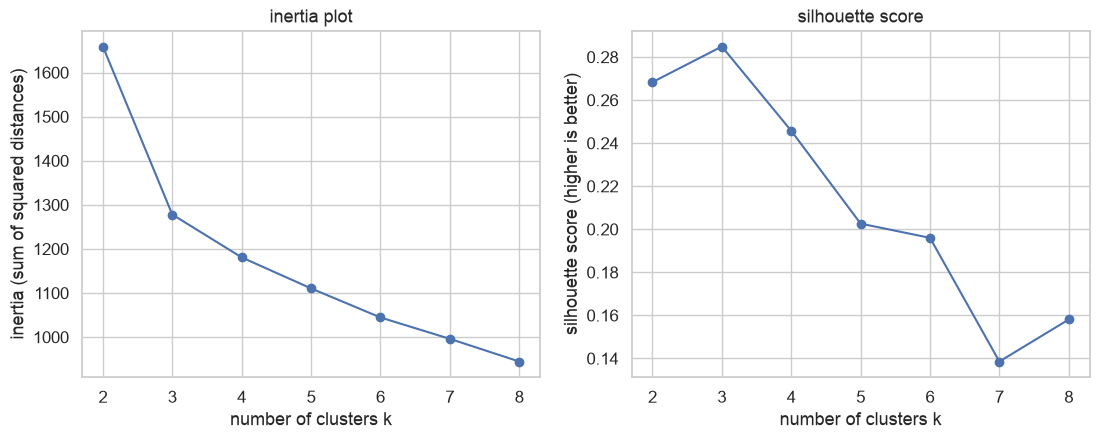

In [14]:
# Left: inertia against k (the inertia plot); right: silhouette score against k
fig, (ax_inertia, ax_silhouette) = plt.subplots(1, 2, figsize=(13, 4.5))
ax_inertia.plot(kmeans_search.index, kmeans_search["inertia"], marker="o")
ax_inertia.set_xlabel("number of clusters k")
ax_inertia.set_ylabel("inertia (sum of squared distances)")
ax_inertia.set_title("inertia plot")

ax_silhouette.plot(kmeans_search.index, kmeans_search["silhouette"], marker="o")
ax_silhouette.set_xlabel("number of clusters k")
ax_silhouette.set_ylabel("silhouette score (higher is better)")
ax_silhouette.set_title("silhouette score")
plt.show()

**What do you see?** Inertia falls from 1,659 at k = 2 to 1,278 at k = 3, a drop of 381. After that, each extra cluster saves much less: 97 from k = 3 to k = 4, and about 70 or less for every later step. So the curve bends (the "elbow") at k = 3. The silhouette score is highest at k = 3 (0.285), close to k = 2 (0.268), and lower from k = 4 on (0.246 and less). Both plots point to three clusters.

The scores are averages. The 2D map shows what a k means in practice: four of the clusterings side by side.

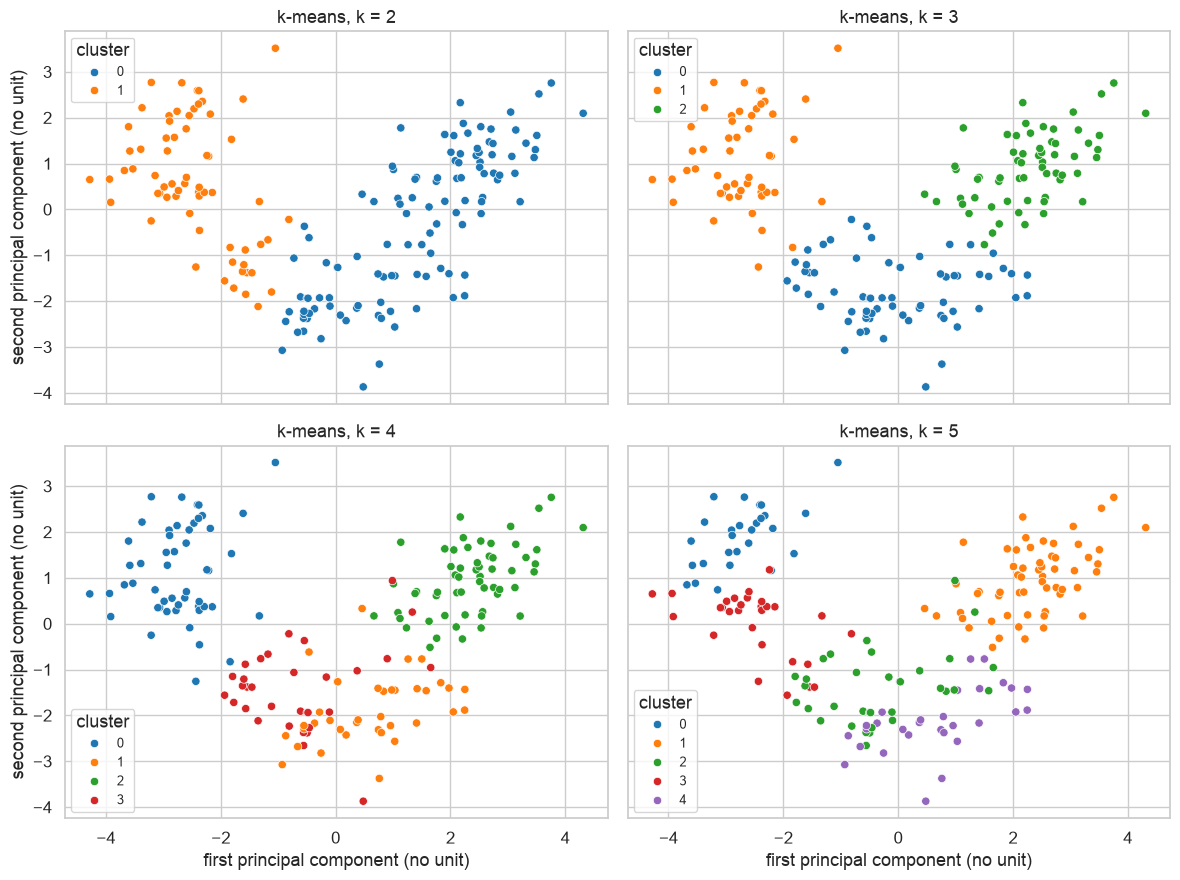

In [15]:
# One map per k in a 2 x 2 grid; sharex and sharey give all four the same axes;
# axes.flat runs through the four panels one by one
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
for ax, number_of_clusters in zip(axes.flat, [2, 3, 4, 5]):
    # The labels of this k, from the loop of 6.2
    cluster_labels = kmeans_cluster_by_k[number_of_clusters]
    # The same one-line map as in 6.1, drawn into this panel
    sns.scatterplot(x=wines_pca_2d[:, 0], y=wines_pca_2d[:, 1], hue=cluster_labels, palette="tab10", ax=ax)
    ax.legend(title="cluster", fontsize=9)
    ax.set_title(f"k-means, k = {number_of_clusters}")
    ax.set_xlabel("first principal component (no unit)")
    ax.set_ylabel("second principal component (no unit)")
# tight_layout leaves enough space between the panels for their labels
fig.tight_layout()
plt.show()

**What do you see?** The wines lie on a curved band with three clouds: at the upper left, at the bottom and at the upper right. With k = 2, k-means puts the bottom and the right cloud into one cluster. With k = 3, each cloud becomes one cluster. With k = 4 and k = 5, k-means splits the clouds further into parts that touch each other on the map.

We choose **k = 3**: it has the highest silhouette score, the inertia plot bends at 3, and the map shows three clouds.

In a supervised search, `GridSearchCV` gives `best_estimator_`. Here we search by hand with a loop (6.2), so we pick the winner ourselves. The table `kmeans_search` has one row per k, and its row labels (the index) are the k values 2 to 8. Three steps:
1. `kmeans_search["silhouette"]` selects the silhouette column: seven scores, each labelled with its k.
2. `.idxmax()` returns the **label** of the largest score, which is the k, not the score itself (`.max()` would give the score). Compare `best_params_`: it also answers "which setting won".
3. `kmeans_cluster_by_k[best_k]` looks the k up in the dictionary of 6.2 that holds the cluster labels of every k, like `best_estimator_.predict(...)` would. We keep these labels as `wine_cluster`.

`kmeans_search.loc[best_k, "silhouette"]` reads one cell of the table by its labels: the row labelled `best_k` and the column `silhouette`. `.loc` works with labels, so `best_k = 3` means the row labelled 3, not the third row.

In [16]:
# idxmax returns the label of the largest silhouette score; the labels of the table are the k values, so this is the best k
# (best_k is like best_params_ of a grid search; int() turns the NumPy number into a plain Python integer)
best_k = int(kmeans_search["silhouette"].idxmax())
# Look up the cluster labels (one number per wine) that the loop of 6.2 stored for this k
wine_cluster = kmeans_cluster_by_k[best_k]
# The scores of the chosen clustering: .loc[row label, column name] reads one cell of the table;
# np.bincount counts the wines per cluster number 0, 1, 2; :.3f and :.0f print 3 and 0 decimals
print(f"k-means, k = {best_k}: silhouette {kmeans_search.loc[best_k, 'silhouette']:.3f}, "
      f"inertia {kmeans_search.loc[best_k, 'inertia']:.0f}, wines per cluster {np.bincount(wine_cluster).tolist()}")

k-means, k = 3: silhouette 0.285, inertia 1278, wines per cluster [65, 51, 62]


### 6.3 From clusters to a decision: what the clusters mean

A cluster number is only a label. Nobody can plan a tasting evening around "cluster 1", so the last job of a clustering is to **translate** every group into words and into an action. These four steps hold for any clustering; a marketing department takes the same steps with customer segments.

1. **Profile**: describe each cluster with the mean of every measurement, in the original units that people understand.
2. **See what stands out**: in scaled units, find the measurements where the cluster lies far above or far below the average wine. These define the cluster.
3. **Name and check**: give each cluster a short name for what stands out, and check the names against a column the clustering never saw.
4. **Act**: decide what the merchant does differently for each named group.

**Step 1.** `wines.groupby(wine_cluster).mean()` gives the mean of every measurement per k-means cluster of k = 3, in the original units; `.T` puts one measurement per row. The clusters hold 65, 51 and 62 wines.

In [17]:
# Mean of all 13 measurements per cluster, in the original units; one column per cluster
cluster_profiles = wines.groupby(wine_cluster).mean().T.round(2)
cluster_profiles.columns = [f"cluster {cluster_number}" for cluster_number in cluster_profiles.columns]
cluster_profiles

,cluster 0,cluster 1,cluster 2
alcohol,12.25,13.13,13.68
malic_acid,1.90,3.31,2.00
ash,2.23,2.42,2.47
alcalinity_of_ash,20.06,21.24,17.46
magnesium,92.74,98.67,107.97
total_phenols,2.25,1.68,2.85
flavanoids,2.05,0.82,3.00
nonflavanoid_phenols,0.36,0.45,0.29
proanthocyanins,1.62,1.15,1.92
color_intensity,2.97,7.23,5.45


**Step 2.** The units differ from row to row, so the table is hard to compare across measurements. A heatmap of the same means in scaled units (standard deviations from the mean of all wines) shows at a glance which measurements are high or low in each cluster.

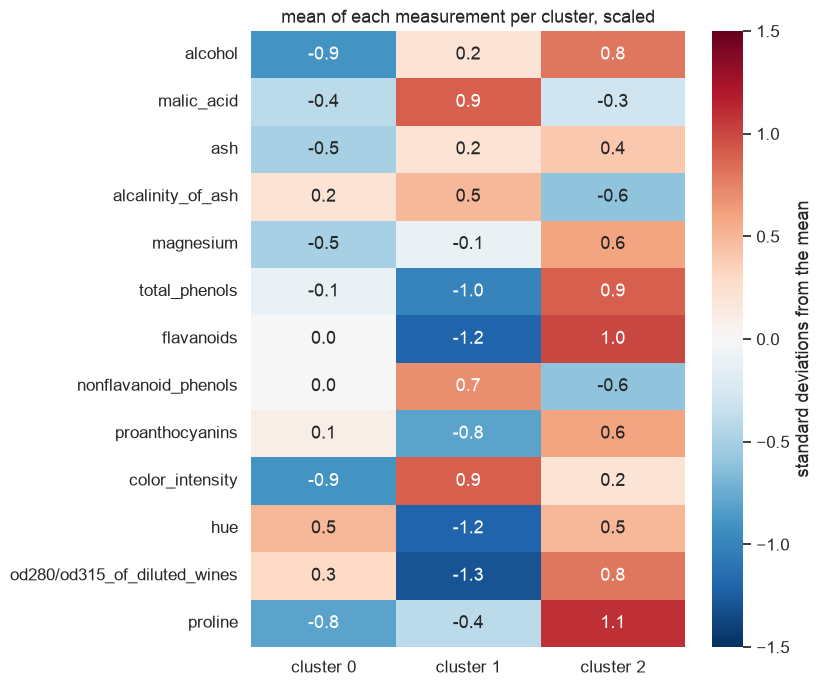

In [18]:
# Cluster means of the scaled columns: 0 is the average wine, +1 one standard deviation above it
# round(1) and replace(-0.0, 0.0) show a tiny negative mean, rounded to -0.0, as 0.0
scaled_profiles = scaled_wines.groupby(wine_cluster).mean().T.round(1).replace(-0.0, 0.0)
scaled_profiles.columns = [f"cluster {cluster_number}" for cluster_number in scaled_profiles.columns]
# annot=True writes each value in its cell; cmap="RdBu_r" shows high values red, low values blue, 0 white
fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(scaled_profiles, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-1.5, vmax=1.5, ax=ax,
            cbar_kws={"label": "standard deviations from the mean"})
ax.set_title("mean of each measurement per cluster, scaled")
plt.show()

The heatmap has 13 rows and 3 clusters: 39 cells are slow to read. The next cell lists, for each cluster, the three measurements with the highest and the three with the lowest scaled mean. These six values are what makes the cluster different from the average wine.

In [19]:
# Scaled means per cluster, one row per measurement, one column per cluster (not rounded yet)
unrounded_profiles = scaled_wines.groupby(wine_cluster).mean().T
stand_out_rows = []
for cluster_number in unrounded_profiles.columns:
    # sort_values orders the 13 means of this cluster from the lowest to the highest
    ordered = unrounded_profiles[cluster_number].sort_values()
    stand_out_rows.append({
        "cluster": f"cluster {cluster_number}",
        # tail(3) holds the three highest means; [::-1] puts the highest first
        "highest above average": ", ".join(f"{measurement} ({value:+.1f})" for measurement, value in ordered.tail(3)[::-1].items()),
        # head(3) holds the three lowest means, the lowest first
        "lowest below average": ", ".join(f"{measurement} ({value:+.1f})" for measurement, value in ordered.head(3).items()),
    })
cluster_stand_out = pd.DataFrame(stand_out_rows).set_index("cluster")
cluster_stand_out

,highest above average,lowest below average
cluster,,
cluster 0,"hue (+0.5), od280/od315_of_diluted_wines (+0.3...","alcohol (-0.9), color_intensity (-0.9), prolin..."
cluster 1,"color_intensity (+0.9), malic_acid (+0.9), non...","od280/od315_of_diluted_wines (-1.3), flavanoid..."
cluster 2,"proline (+1.1), flavanoids (+1.0), total_pheno...","alcalinity_of_ash (-0.6), nonflavanoid_phenols..."


**What do you see?** Cluster 0 is defined by what it lacks: `alcohol` (−0.9), `color_intensity` (−0.9) and `proline` (−0.8) are low, and nothing is strongly high. Cluster 1 is defined by a deep colour (`color_intensity` +0.9) and much malic acid (+0.9), together with very few phenols: `od280/od315_of_diluted_wines` (−1.3), `flavanoids` (−1.2) and `hue` (−1.2) are the lowest. Cluster 2 is rich in `proline` (+1.1), `flavanoids` (+1.0) and `total_phenols` (+0.9). A value near 0 does not describe a cluster; only the large values do.

**What do you see?** The three clusters read as three styles of wine.
- **Cluster 0** (65 wines): lighter wines, with the least alcohol (12.25%), a pale colour (colour intensity 2.97), little magnesium and the least proline (510 mg per litre).
- **Cluster 1** (51 wines): deep in colour (7.23) but low in phenols: the fewest flavanoids (0.82) and total phenols (1.68), the lowest hue (0.69), and the most malic acid (3.31 g per litre).
- **Cluster 2** (62 wines): strong, rich wines, with the most alcohol (13.68%), flavanoids (3.00) and proline (1,100 mg per litre).

**Step 3.** The merchant can give the groups names such as "light", "dark and soft" and "strong". A name is only a proposal until it is checked.

A name should also hold against a column the clustering never saw, such as price, region or sales in a real project. Here we use the grape variety `cultivar` that we kept aside. `pd.crosstab` counts the wines for every pair of cluster and variety; `normalize="index"` turns every row into shares that add up to 1.

In [20]:
# Rows: the three clusters; columns: the grape variety 0, 1, 2 (never used by the clustering).
# normalize="index" makes every row add up to 1; pd.Series gives the cluster numbers the name "cluster"
cluster_by_cultivar = pd.crosstab(pd.Series(wine_cluster, name="cluster"), cultivar, normalize="index").round(2)
cluster_by_cultivar

cultivar,0,1,2
cluster,,,
0,0.00,1.00,0.00
1,0.00,0.06,0.94
2,0.95,0.05,0.00


**What do you see?** Every cluster is almost one grape variety: all 65 wines of cluster 0 are variety 1, 94% of cluster 1 (48 of 51) are variety 2, and 95% of cluster 2 (59 of 62) are variety 0. The names "light", "dark and soft" and "strong" therefore describe real kinds of wine, not an accident of the algorithm. In a real project the merchant has no variety; then the check is a column such as price or sales, or a taste test of a few wines per group.

**Step 4: from names to actions.** The table is a proposal of the analyst. The profile gives the first two columns; the actions are decisions of the merchant, who can change them.

| Cluster | Name | Recognise it by | What the merchant can do |
|---|---|---|---|
| 0 (65 wines) | light | the least alcohol (12.25%), a pale colour (colour intensity 2.97), the least proline (510 mg per litre) | one shelf section for light, easy bottles; start a tasting evening with them |
| 1 (51 wines) | dark and soft | the deepest colour (7.23), the fewest flavanoids (0.82) and phenols (1.68), the lowest hue (0.69), the most malic acid (3.31 g per litre) | one shelf section for dark wines with little dry feel in the mouth; a separate tasting for guests who dislike dry wine |
| 2 (62 wines) | strong | the most alcohol (13.68%), flavanoids (3.00) and proline (1,100 mg per litre) | a shelf section for rich, strong bottles; a tasting evening for guests who like full-bodied wines |

Two questions tell the merchant whether k = 3 is useful. If two groups would get the same action, k is too large: merge them. If one group needs two different actions, k is too small: go back to 6.2 and try a larger k. This is the loop of the slides, *Clustering is a loop with people in it*: the algorithm proposes, the people who use the groups decide.

The 2D map keeps only part of the spread: 55% of it. A 3D map of the first three principal components keeps 67%, and an interactive one lets you turn the cloud. **Drag** to turn it, **scroll** to zoom, and **hover** over a wine to read its cluster and four of its measurements. plotly draws figures you can move in the browser; `px.scatter_3d` takes a table and the names of its columns.

The next cell has two kinds of lines, and neither is statistics:
- **Display setting.** `pio.renderers.default = ...` only tells plotly *how to show* a figure. This setting stores the figure inside the notebook file, so it is still there when you reopen the notebook, and it loads the plotly library from the internet instead of copying it into every figure (a figure then needs an internet connection to open). It changes nothing in the figure itself. If a plotly figure stays blank in your editor, this is the line to check.
- **Preparing the table for plotly.** plotly draws from a table in which every column is one thing to show. The table `wines_pca_3d` already has the three principal components, `PC1`, `PC2` and `PC3`, which become x, y and z. The next two blocks add what we want to see on top of them: a column `cluster` with the name of the cluster of every wine, written as text such as "cluster 2" so that plotly gives each cluster its own colour and legend entry instead of a colour scale for numbers; and four of the 13 original measurements, copied from `wines`, so that they appear in the box over a dot when you hover. None of these columns changes the position of a dot.

In [21]:
import plotly.express as px
import plotly.io as pio

# Display setting only, no effect on the figure: save the figure inside the notebook file
# and load the plotly library from the internet when the notebook is opened
pio.renderers.default = "plotly_mimetype+notebook_connected"

# Three principal components this time: one table with the columns PC1, PC2 and PC3 (the x, y and z of each wine)
wines_pca_3d = pd.DataFrame(PCA(n_components=3).fit_transform(scaled_wines), columns=["PC1", "PC2", "PC3"])
# A text column with the cluster of every wine, e.g. "cluster 2": plotly colours by it and lists the clusters in the legend
wines_pca_3d["cluster"] = [f"cluster {cluster_number}" for cluster_number in wine_cluster]
# Copy four of the 13 original measurements into the table, one column each; they only appear when you hover over a dot
for column in ["alcohol", "flavanoids", "color_intensity", "proline"]:
    wines_pca_3d[column] = wines[column]

# One dot per wine; color and symbol by cluster; hover_data lists what the box shows over a dot
cluster_figure = px.scatter_3d(wines_pca_3d, x="PC1", y="PC2", z="PC3", color="cluster", symbol="cluster",
                               hover_data=["alcohol", "flavanoids", "color_intensity", "proline"],
                               category_orders={"cluster": sorted(wines_pca_3d["cluster"].unique())},
                               title=f"k-means, k = {best_k}: the first three principal components",
                               width=800, height=600)
# Smaller dots, so the clusters do not hide each other
cluster_figure.update_traces(marker_size=4)
cluster_figure.show()

**A 2D or 3D picture is a shadow, and the metrics decide.** The scatter plot is only a help for the eyes. Both pictures show the wines in fewer columns than the clustering uses, so the same clusters can look very different in different pictures. Two made-up examples with three columns each show this. This time k-means clusters them (`KMeans(n_clusters=2)` on **all three columns**), and we draw the same clusters twice: in a picture of the **first two columns** (x and y) and in a picture of **all three columns** (x, y and z).

The silhouette score belongs to the clustering, not to the picture: it is computed once, from the three columns and the cluster labels, so it is **the same number** in both titles. What changes between the pictures is only how the clusters look. This is the same situation as the wines: k-means works on the 13 scaled columns, and the PCA map or the 3D map only draws the result.

The two examples:
- **Example A: two equal groups that differ only in the third column.** Seen from the front (x and y), the two clusters lie on top of each other.
- **Example B: a small group far away in the third column.** Seen from the front, its 8 points sit inside the big cloud, as if they were ordinary.

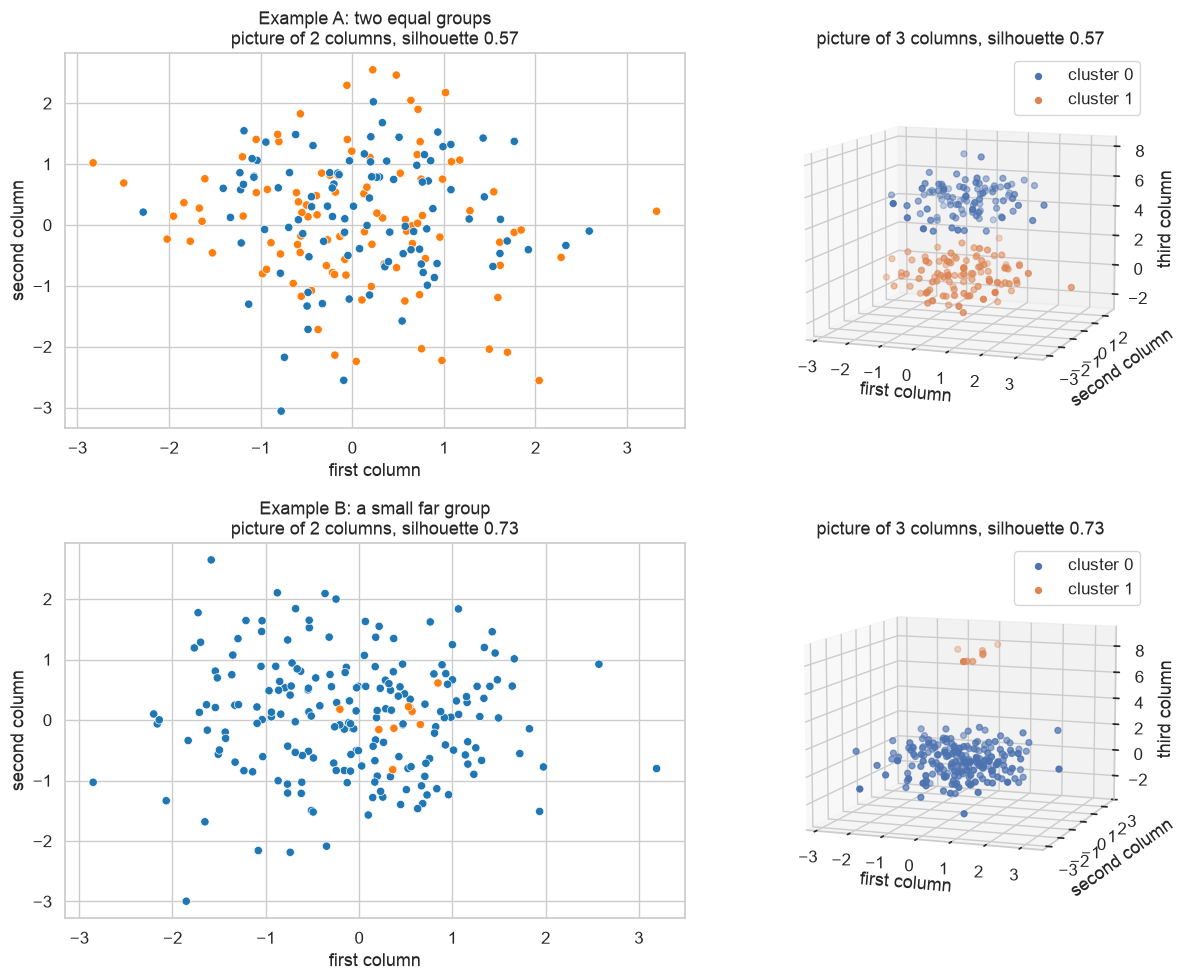

In [22]:
# Two made-up data sets with three columns each
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3D axes)
from sklearn.cluster import KMeans

example_rng = np.random.default_rng(3)

# Example A: 100 points around (0, 0, 0) and 100 around (0, 0, 5): the groups differ only in the third column
points_a = np.vstack([example_rng.normal(loc=[0, 0, 0], scale=1.0, size=(100, 3)),
                      example_rng.normal(loc=[0, 0, 5], scale=1.0, size=(100, 3))])

# Example B: a cloud of 200 points, plus 8 points whose first two columns look ordinary
# but whose third column is far away (around 8)
cloud = example_rng.normal(loc=0, scale=1.0, size=(200, 3))
far_points = np.column_stack([example_rng.normal(0, 0.5, size=(8, 2)), example_rng.normal(8, 0.5, size=8)])
points_b = np.vstack([cloud, far_points])

# One row per example: left the picture in two columns (x and y), right all three columns
fig = plt.figure(figsize=(13, 10))
for row, (example_name, points) in enumerate([("Example A: two equal groups", points_a),
                                              ("Example B: a small far group", points_b)]):
    # k-means works on all three columns; the picture is only used afterwards to draw its result
    clusters = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(points)
    # The silhouette score of this clustering, from the three columns and the labels: one number per example
    clustering_silhouette = silhouette_score(points, clusters)

    ax_2d = fig.add_subplot(2, 2, 2 * row + 1)
    sns.scatterplot(x=points[:, 0], y=points[:, 1], hue=clusters, palette="tab10", ax=ax_2d, legend=False)
    ax_2d.set_title(f"{example_name}\npicture of 2 columns, silhouette {clustering_silhouette:.2f}")
    ax_2d.set_xlabel("first column")
    ax_2d.set_ylabel("second column")

    # projection="3d" makes a 3D axes; scatter takes x, y and z; view_init turns the camera
    ax_3d = fig.add_subplot(2, 2, 2 * row + 2, projection="3d")
    for cluster_number in (0, 1):
        in_cluster = clusters == cluster_number
        ax_3d.scatter(points[in_cluster, 0], points[in_cluster, 1], points[in_cluster, 2], s=18, label=f"cluster {cluster_number}")
    ax_3d.view_init(elev=10, azim=-70)
    ax_3d.set_title(f"picture of 3 columns, silhouette {clustering_silhouette:.2f}")
    ax_3d.set_xlabel("first column")
    ax_3d.set_ylabel("second column")
    ax_3d.set_zlabel("third column")
    ax_3d.legend()
fig.tight_layout()
plt.show()

**What do you see?** In example A, the 2D picture shows one round cloud, with the two clusters mixed, while the 3D picture shows two clouds, one above the other. In example B, the 8 far points hide inside the big cloud in 2D and float far above it in 3D. The pictures look very different, yet the silhouette of the clustering is the same in both titles: 0.57 for example A and 0.73 for example B. The score comes from the clustering on all three columns, and the picture does not enter it.

The lesson for the wines: the 2D PCA map or the 3D map shows the clusters in two or three PCA columns (55% or 67% of the spread). On the map two clusters can overlap, as in example A, although k-means separated them using all 13 columns. The picture helps us look; the **silhouette score on all 13 scaled columns** (0.285 for k = 3) and the stability check in 6.5 are the evidence.

### 6.4 A second method: agglomerative clustering

`AgglomerativeClustering` starts with every wine as its own cluster and merges the two closest clusters again and again. With `linkage="ward"` (the default) it merges the pair that raises the inertia the least. Unlike k-means, it has no random start and does not need round clusters of similar size. We run the same loop over k = 2 to 8 and plot both silhouette curves.

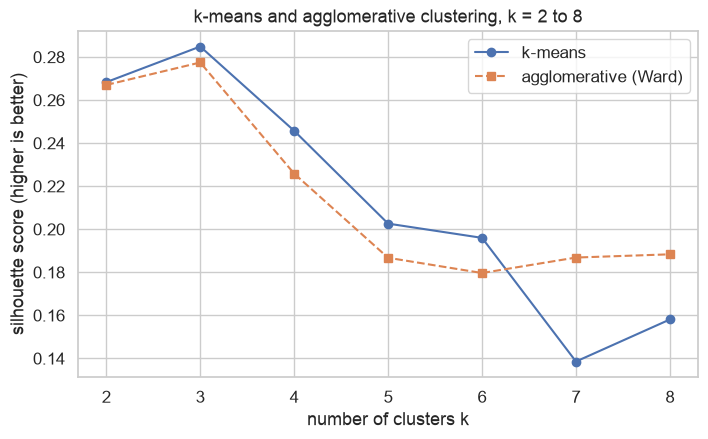

In [23]:
from sklearn.cluster import AgglomerativeClustering

# The same loop as for k-means: one agglomerative clustering per k
agglomerative_cluster_by_k = {}
agglomerative_silhouette = {}
for number_of_clusters in range(2, 9):
    agglomerative_pipeline = Pipeline([("scaling", StandardScaler()),
                                       ("agglomerative", AgglomerativeClustering(n_clusters=number_of_clusters, linkage="ward"))])
    agglomerative_cluster_by_k[number_of_clusters] = agglomerative_pipeline.fit_predict(wines)
    agglomerative_silhouette[number_of_clusters] = silhouette_score(scaled_wines, agglomerative_cluster_by_k[number_of_clusters])

# Both silhouette curves on one plot; the dashed line is agglomerative clustering
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(kmeans_search.index, kmeans_search["silhouette"], marker="o", label="k-means")
ax.plot(list(agglomerative_silhouette), list(agglomerative_silhouette.values()), marker="s", linestyle="--",
        label="agglomerative (Ward)")
ax.set_xlabel("number of clusters k")
ax.set_ylabel("silhouette score (higher is better)")
ax.set_title("k-means and agglomerative clustering, k = 2 to 8")
ax.legend()
plt.show()

**What do you see?** Agglomerative clustering gives almost the same curve. It is also best at k = 3 (0.277, against 0.285 for k-means) and close at k = 2. For k = 7 and 8 it is ahead of k-means, but both methods are far below their best there. The second method confirms k = 3.

The two clusterings at k = 3 on the same map:

agglomerative (Ward), k = 3: silhouette 0.277, inertia 1305, wines per cluster [58, 56, 64]


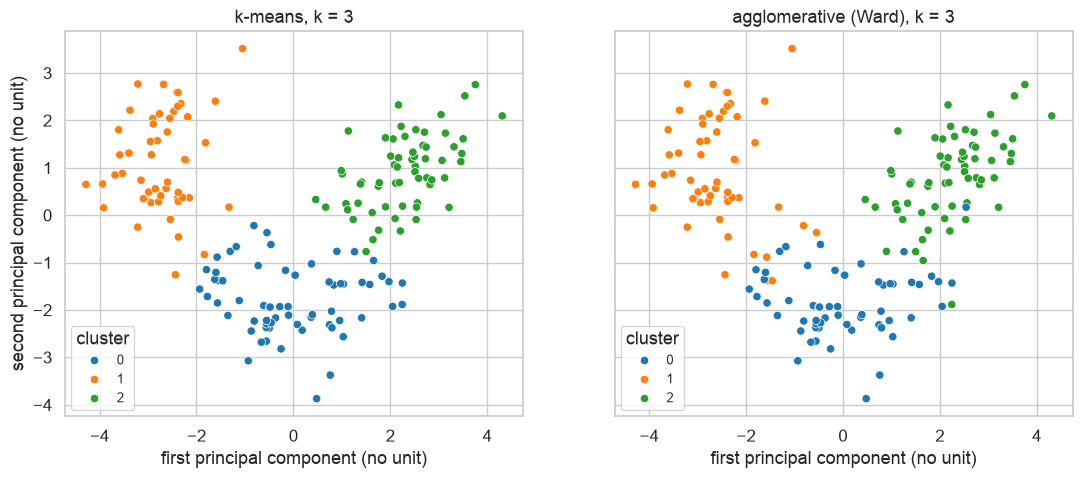

In [24]:
# The agglomerative clustering with the chosen k, from the loop above
agglomerative_cluster = agglomerative_cluster_by_k[best_k]
agglomerative_silhouette_best = silhouette_score(scaled_wines, agglomerative_cluster)
# AgglomerativeClustering has no inertia_, so we compute it: groupby(...).transform("mean")
# gives every wine the mean of its own cluster; we sum the squared distances to it
distance_to_cluster_mean = scaled_wines - scaled_wines.groupby(agglomerative_cluster).transform("mean")
agglomerative_inertia = (distance_to_cluster_mean ** 2).to_numpy().sum()
print(f"agglomerative (Ward), k = {best_k}: silhouette {agglomerative_silhouette_best:.3f}, "
      f"inertia {agglomerative_inertia:.0f}, wines per cluster {np.bincount(agglomerative_cluster).tolist()}")

# The k-means and the agglomerative clusters side by side on the same 2D map
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
panels = [(f"k-means, k = {best_k}", wine_cluster), (f"agglomerative (Ward), k = {best_k}", agglomerative_cluster)]
for ax, (clustering_name, cluster_labels) in zip(axes, panels):
    # The same one-line map as in 6.1, drawn into this panel
    sns.scatterplot(x=wines_pca_2d[:, 0], y=wines_pca_2d[:, 1], hue=cluster_labels, palette="tab10", ax=ax)
    ax.legend(title="cluster", fontsize=9)
    ax.set_title(clustering_name)
    ax.set_xlabel("first principal component (no unit)")
    ax.set_ylabel("second principal component (no unit)")
plt.show()

**What do you see?** The two methods find the same three clouds. They differ only for wines at the borders: the bottom cluster holds 65 wines with k-means and 58 with agglomerative clustering, the upper left one 51 and 56, the upper right one 62 and 64. A few wines between the bottom and the upper left cloud change their group.

### 6.5 Do the clusters come back?

A useful clustering should not depend on the exact wines we happen to have. We draw 100 **bootstrap samples**: 178 wines drawn with replacement, so some wines appear twice and some not at all. We refit k-means on each, assign all 178 wines to the new centres with `predict`, and compare with `wine_cluster` by the **adjusted Rand index** (ARI): 1 means the same groups (whatever their numbers), 0 means no more agreement than chance.

In [25]:
from sklearn.metrics import adjusted_rand_score

# A separate random generator for the stability check; seed 1 makes it repeatable
stability_rng = np.random.default_rng(1)
stability_scores = []
for repetition in range(100):
    # 178 row positions drawn with replacement
    sample_rows = stability_rng.integers(0, len(wines), size=len(wines))
    bootstrap_pipeline = Pipeline([("scaling", StandardScaler()),
                                   ("kmeans", KMeans(n_clusters=best_k, n_init=10, random_state=repetition))])
    bootstrap_pipeline.fit(wines.iloc[sample_rows])
    # predict assigns every wine to its nearest new centre; ARI compares with the original clusters
    stability_scores.append(adjusted_rand_score(wine_cluster, bootstrap_pipeline.predict(wines)))
print(f"ARI with the original clusters over 100 refits: mean {np.mean(stability_scores):.3f}, "
      f"lowest {np.min(stability_scores):.3f}, highest {np.max(stability_scores):.3f}")

ARI with the original clusters over 100 refits: mean 0.941, lowest 0.865, highest 1.000


**What do you see?** Over 100 refits on bootstrap samples, the ARI with the original clusters is 0.941 on average, never below 0.865, and sometimes 1.000. The three groups come back almost unchanged when the wines change a little; only a few border wines switch.

## 7 Report the results

One table puts the clusterings side by side: k-means with k = 8, the tuned one, its neighbours k = 2 and k = 4, and agglomerative clustering. The last column is an **outside check**: the ARI between the clusters and the grape variety that we kept aside in step 2. The variety was never used to build or to choose the clusters; it only tells us whether the groups match something real.

In [26]:
# The clusterings to report, by name; each entry holds the cluster label of every wine
reported_clusterings = {
    "k-means, k = 8": kmeans_8_cluster,
    "k-means, k = 2": kmeans_cluster_by_k[2],
    f"k-means, k = {best_k} (chosen)": wine_cluster,
    "k-means, k = 4": kmeans_cluster_by_k[4],
    f"agglomerative (Ward), k = {best_k}": agglomerative_cluster,
}
# One row per clustering: silhouette, inertia and the ARI with the grape variety
report_rows = []
for clustering_name, cluster_labels in reported_clusterings.items():
    # Inertia: squared distances from each wine to the mean of its cluster, summed (as in 6.4)
    distance_to_cluster_mean = scaled_wines - scaled_wines.groupby(cluster_labels).transform("mean")
    report_rows.append({
        "clustering": clustering_name,
        "silhouette": silhouette_score(scaled_wines, cluster_labels),
        "inertia": (distance_to_cluster_mean ** 2).to_numpy().sum(),
        "ARI with variety": adjusted_rand_score(cultivar, cluster_labels),
    })
test_results = pd.DataFrame(report_rows).set_index("clustering").round(3)
test_results

,silhouette,inertia,ARI with variety
clustering,,,
"k-means, k = 8",0.158,944.559,0.406
"k-means, k = 2",0.268,1659.008,0.389
"k-means, k = 3 (chosen)",0.285,1277.928,0.897
"k-means, k = 4",0.246,1180.738,0.707
"agglomerative (Ward), k = 3",0.277,1305.049,0.790


**What do you see?** k-means with k = 3 has the highest silhouette score (0.285). It also matches the grape varieties best (ARI 0.897), although it never saw them. k = 2 merges two varieties (ARI 0.389), and k = 8 splits them (ARI 0.406). Agglomerative clustering is close on the silhouette (0.277) but agrees less with the varieties (ARI 0.790). The inertia is lowest for k = 8, as it always is for the largest k, so it cannot choose k on its own.

### 7.1 How sure is each score?

The 178 wines are one sample of the wines of this region. Another sample would give a slightly different silhouette score. A **95% confidence interval** shows how far the score could move for that reason: over many samples, 95 of 100 such intervals contain the true score.

The silhouette score has no simple formula for its interval, so we use the **bootstrap**. The fitted clusterings stay fixed; only the wines are drawn again. The silhouette score is the mean of one silhouette value per wine, and `silhouette_samples(X, cluster_labels)` returns these 178 values. So:

1. Compute the silhouette value of every wine once, with its fixed cluster label.
2. Draw 178 wines **with replacement**: some wines appear twice, some not at all. The mean of their silhouette values is the score of this resample.
3. Repeat 1,000 times. The middle 95% of the 1,000 scores, from the 2.5th to the 97.5th percentile, is the interval.

`rng.integers(0, n, size=(1000, n))` draws the row positions of all 1,000 resamples at once, one resample per row of the array. For the ARI with the grape variety we recompute `adjusted_rand_score` on the labels of the resampled wines.

In [27]:
# 1,000 resamples of the wines; each row of resampled_rows holds the positions of one resample
rng = np.random.default_rng(0)
n_resamples = 1000
n_wines = len(wines)
resampled_rows = rng.integers(0, n_wines, size=(n_resamples, n_wines))

from sklearn.metrics import silhouette_samples

# The silhouette score and the ARI of every clustering on every resample; nothing is refitted
cultivar_array = cultivar.to_numpy()
bootstrap_silhouette = {}
bootstrap_ari = {}
for clustering_name, cluster_labels in reported_clusterings.items():
    # One silhouette value per wine; their mean over all 178 wines is the silhouette score
    silhouette_per_wine = silhouette_samples(scaled_wines, cluster_labels)
    # silhouette_per_wine[resampled_rows] is a 1,000 x 178 array; mean(axis=1) gives one score per resample
    bootstrap_silhouette[clustering_name] = silhouette_per_wine[resampled_rows].mean(axis=1)
    bootstrap_ari[clustering_name] = np.array(
        [adjusted_rand_score(cultivar_array[rows], cluster_labels[rows]) for rows in resampled_rows])

# The interval of each score: the 2.5th and the 97.5th percentile of its 1,000 values
interval_rows = []
for clustering_name in reported_clusterings:
    silhouette_lower, silhouette_upper = np.percentile(bootstrap_silhouette[clustering_name], [2.5, 97.5])
    ari_lower, ari_upper = np.percentile(bootstrap_ari[clustering_name], [2.5, 97.5])
    interval_rows.append({
        "clustering": clustering_name,
        "silhouette": test_results.loc[clustering_name, "silhouette"],
        "silhouette 95% CI": f"{silhouette_lower:.3f} to {silhouette_upper:.3f}",
        "ARI with variety": test_results.loc[clustering_name, "ARI with variety"],
        "ARI 95% CI": f"{ari_lower:.3f} to {ari_upper:.3f}",
    })
score_intervals = pd.DataFrame(interval_rows).set_index("clustering")
score_intervals

,silhouette,silhouette 95% CI,ARI with variety,ARI 95% CI
clustering,,,,
"k-means, k = 8",0.158,0.143 to 0.174,0.406,0.347 to 0.489
"k-means, k = 2",0.268,0.250 to 0.285,0.389,0.307 to 0.485
"k-means, k = 3 (chosen)",0.285,0.266 to 0.305,0.897,0.816 to 0.967
"k-means, k = 4",0.246,0.226 to 0.265,0.707,0.610 to 0.805
"agglomerative (Ward), k = 3",0.277,0.258 to 0.297,0.790,0.684 to 0.895


**What do you see?** With 178 wines, each silhouette interval is about 0.04 wide. The intervals of k-means with k = 3 (0.266 to 0.305), k = 2 (0.250 to 0.285) and agglomerative clustering (0.258 to 0.297) overlap. The ARI with the grape variety is less certain: for k = 3 it lies between 0.816 and 0.967, so on other wines of this region the three groups would still match the varieties closely. Do the overlapping silhouette intervals mean that the clusterings are equally good? Section 7.2 answers this.

**The assumption that matters here.** The bootstrap treats the 178 wines as independent draws from the wines of the region: one wine tells us nothing about the next. That fits a set of different bottles. If the data held several bottles of the same wine, they would have to be resampled together. Two more points are specific to clustering. We resample the silhouette values of the wines, not the wines themselves with a new silhouette computed on the resample: a wine drawn twice sits at distance 0 from its copy, which makes its own cluster look tighter and pushes every score upwards. And the interval shows how the score varies with the wines for fixed clusters; how the clusters themselves vary when we refit is what the stability check in 6.5 shows. No formula with a normal approximation is used here, so the rule of about 10 of each outcome does not apply.

### 7.2 Is one clustering really better? The interval of the difference

The silhouette intervals of k = 2, k = 3 and agglomerative clustering overlap. Many people read this as "the settings are equally good", but that is a common mistake. A comparison of two classmates shows why.

> Anna and Ben take the same exam every year, and the exam is harder in some years than in others. Anna's scores range from 70 to 90, and Ben's from 75 to 95, so the ranges overlap. But in every year, on the same exam, Ben scores about 5 points more than Anna. Is Ben better? Yes. The overlap only shows that the exams vary in difficulty. To compare them, you compare them on the same exam, which is the difference.

Our clusterings are in the same situation: all of them are scored on the **same** resampled wines. A resample with many typical wines raises every score; one with many wines between groups lowers every score. This shared luck makes each interval wide, and it cancels when we subtract one score from the other.

So on every resample we compute the chosen clustering's silhouette minus the other one's, with the same rows for both. The middle 95% of the 1,000 differences is the **95% interval of the difference**:

- the interval lies above 0: the chosen clustering is better separated by about that much; below 0: it is worse;
- the interval contains 0: on these wines we cannot tell the two apart.

In [28]:
# The chosen clustering against each alternative, by name
chosen_name = f"k-means, k = {best_k} (chosen)"
alternatives = ["k-means, k = 2", "k-means, k = 4", f"agglomerative (Ward), k = {best_k}"]

difference_rows = []
silhouette_differences = {}
for other_name in alternatives:
    # The same resampled rows for both clusterings, so each difference compares them on the same wines
    silhouette_differences[other_name] = bootstrap_silhouette[chosen_name] - bootstrap_silhouette[other_name]
    lower, upper = np.percentile(silhouette_differences[other_name], [2.5, 97.5])
    difference_rows.append({
        "comparison": f"{chosen_name} minus {other_name}",
        "difference in silhouette": round(test_results.loc[chosen_name, "silhouette"] - test_results.loc[other_name, "silhouette"], 3),
        "95% CI": f"{lower:+.3f} to {upper:+.3f}",
    })
silhouette_gains = pd.DataFrame(difference_rows).set_index("comparison")
silhouette_gains

,difference in silhouette,95% CI
comparison,,
"k-means, k = 3 (chosen) minus k-means, k = 2",0.017,-0.001 to +0.035
"k-means, k = 3 (chosen) minus k-means, k = 4",0.039,+0.029 to +0.050
"k-means, k = 3 (chosen) minus agglomerative (Ward), k = 3",0.008,+0.004 to +0.011


A histogram of the 1,000 differences against k = 2, the closest neighbour, shows the same as a picture. The solid lines mark the 95% interval, the dashed line a difference of 0, "no difference".

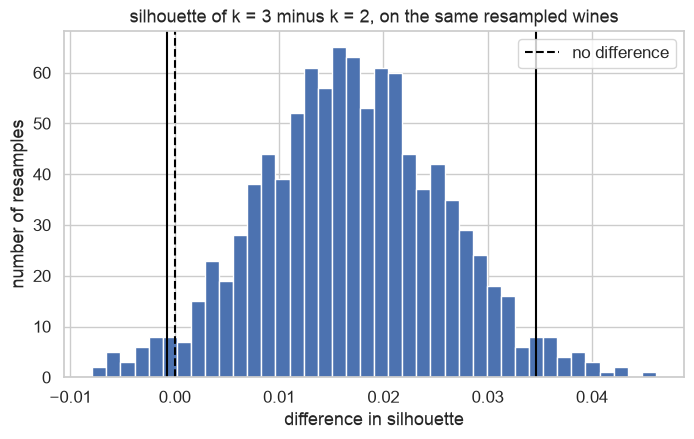

In [29]:
# The 1,000 paired differences of the chosen clustering against k = 2
closest_name = "k-means, k = 2"
differences = silhouette_differences[closest_name]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(differences, bins=40)
# The 95% interval as two solid lines, the value 0 as a dashed line
for bound in np.percentile(differences, [2.5, 97.5]):
    ax.axvline(bound, color="black")
ax.axvline(0, color="black", linestyle="--", label="no difference")
ax.set_title(f"silhouette of k = {best_k} minus k = 2, on the same resampled wines")
ax.set_xlabel("difference in silhouette")
ax.set_ylabel("number of resamples")
ax.legend()
plt.show()

**What do you see?** The table shows three cases.
- **k = 3 against k = 4**: the difference is +0.039, with an interval of +0.029 to +0.050. It lies above 0: three clusters are better separated than four.
- **k-means against agglomerative clustering, k = 3**: the difference is only +0.008, but its interval, +0.004 to +0.011, lies above 0. The separate intervals overlap almost completely, yet on the same wines k-means is ahead on every part of the interval, as Ben was ahead of Anna. The gain is real but small.
- **k = 3 against k = 2**: the difference is +0.017, and most resamples in the histogram favour k = 3. But the interval, −0.001 to +0.035, contains 0 at its lower end. On the silhouette score alone, these wines cannot tell k = 2 and k = 3 apart. The choice of k = 3 rests on the other evidence too: the bend of the inertia plot, the three clouds on the map and the stability.

### 7.3 Use the model on a new input

If the merchant uses the clusters, every new wine needs a group. A new wine arrives as one row of the same 13 lab measurements. The chosen k-means pipeline of 6.2 (k = 3) holds two fitted steps: the scaler, which learned the mean and the standard deviation of each column, and k-means, which learned the three centres. `transform` of the scaler puts the new wine into the scaled units, and `predict` of k-means gives it the number of the nearest centre. Nothing is refitted. `pca_2d.transform` places the new wine on the 2D map of step 6.

Agglomerative clustering and HDBSCAN have no `predict` for new rows: they can only group the wines they were fitted on. This is one reason to deploy k-means.

the new input, 13 measurements of each new wine:
                                  10      140
alcohol                         14.10   12.93
malic_acid                       2.16    2.81
ash                              2.30    2.70
alcalinity_of_ash               18.00   21.00
magnesium                      105.00   96.00
total_phenols                    2.95    1.54
flavanoids                       3.32    0.50
nonflavanoid_phenols             0.22    0.53
proanthocyanins                  2.38    0.75
color_intensity                  5.75    4.60
hue                              1.25    0.77
od280/od315_of_diluted_wines     3.17    2.31
proline                       1510.00  600.00

scaled input: (2, 13) → output: (2,)
predict returns: [2 1]
the same wines in wine_cluster (from the fit): [2 1]
wine 10 belongs to cluster 2: put it on that shelf section
wine 140 belongs to cluster 1: put it on that shelf section

position on the 2D map (x, y), one row per new wine:
[[ 3.48  1.3 ]
 [-2.

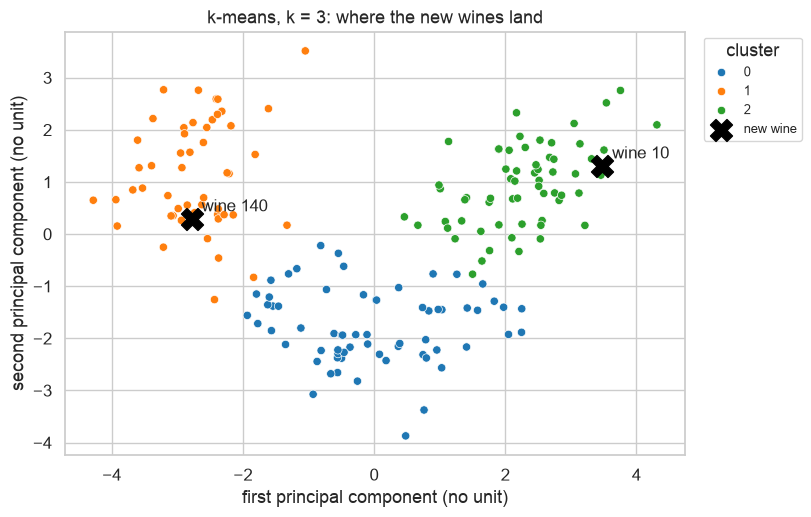

In [30]:
# The chosen k-means pipeline of 6.2, already fitted: scaling step, then k-means with k = 3
chosen_kmeans_pipeline = kmeans_pipeline_by_k[best_k]
fitted_scaler = chosen_kmeans_pipeline.named_steps["scaling"]
chosen_kmeans = chosen_kmeans_pipeline.named_steps["kmeans"]

# We have no new wine, and 13 lab values cannot be made up in a realistic way. So we treat
# wines 10 and 140 as if they had just arrived from the lab. The model has seen them, so the
# output must match their clusters in wine_cluster; a really new wine would go the same way.
# wines.loc[[10, 140]] returns a small DataFrame: two rows, all 13 columns the model needs
new_wines = wines.loc[[10, 140]]
# .T shows one measurement per row, so all 13 values of both wines fit on the screen
print("the new input, 13 measurements of each new wine:")
print(new_wines.T)

# transform uses the means and standard deviations learned in 6.2; it returns a 2 x 13 array
new_wines_scaled = fitted_scaler.transform(new_wines)
# predict returns the number of the nearest of the three centres, one number per new wine
new_wine_cluster = chosen_kmeans.predict(new_wines_scaled)
print("\nscaled input:", new_wines_scaled.shape, "→ output:", new_wine_cluster.shape)
print("predict returns:", new_wine_cluster)
print("the same wines in wine_cluster (from the fit):", wine_cluster[[10, 140]])
for wine_number, cluster_number in zip(new_wines.index, new_wine_cluster):
    print(f"wine {wine_number} belongs to cluster {cluster_number}: put it on that shelf section")

# pca_2d.transform places the scaled wines on the 2D map; pd.DataFrame gives it the column names it was fitted with
new_wines_pca_2d = pca_2d.transform(pd.DataFrame(new_wines_scaled, columns=wines.columns))
print("\nposition on the 2D map (x, y), one row per new wine:")
print(new_wines_pca_2d.round(2))

# The map of 6.2 with k = 3, the same one-line plot, and a large black cross for each new wine
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(x=wines_pca_2d[:, 0], y=wines_pca_2d[:, 1], hue=wine_cluster, palette="tab10", ax=ax)
ax.scatter(new_wines_pca_2d[:, 0], new_wines_pca_2d[:, 1], marker="X", s=250, color="black", label="new wine")
# ax.text writes the wine number next to its cross
for wine_number, (x, y) in zip(new_wines.index, new_wines_pca_2d):
    ax.text(x + 0.15, y + 0.15, f"wine {wine_number}", fontsize=12)
ax.set_title(f"k-means, k = {best_k}: where the new wines land")
ax.set_xlabel("first principal component (no unit)")
ax.set_ylabel("second principal component (no unit)")
ax.legend(title="cluster", fontsize=9, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**What do you see?** The input is two rows of 13 lab values; the output of `predict` is one cluster number per wine: `[2 1]`. Wine 10, with 14.10% alcohol, 3.32 flavanoids and 1,510 mg of proline per litre, goes to cluster 2, the strong, rich wines. Wine 140, with only 0.50 flavanoids and a hue of 0.77, goes to cluster 1, the dark wines low in phenols. Both numbers are the same as in `wine_cluster`, as they must be, because k-means gives every wine the number of its nearest centre. On the map, wine 10 lands at x = 3.48, y = 1.30 in the upper right cloud, and wine 140 at x = −2.78, y = 0.29 in the upper left cloud. A really new wine from the lab would go through the same two lines: `transform`, then `predict`.

**Finding.** k-means with k = 3 on the 13 scaled measurements groups the 178 wines into three stable groups (65, 51 and 62 wines; mean ARI 0.941 over 100 refits) with clear profiles: light wines, dark wines low in phenols, and strong wines rich in flavanoids and proline. Its silhouette score is 0.285 (95% interval 0.266 to 0.305), better than k = 4 (difference +0.039, interval +0.029 to +0.050) and slightly better than agglomerative clustering (+0.008, interval +0.004 to +0.011), while against k = 2 the interval of the difference (−0.001 to +0.035) contains 0, so the bend of the inertia plot and the maps decide there. One limitation: a silhouette near 0.29 means that the groups touch, so wines near a border may fit two groups; the match with the grape varieties (ARI 0.897, interval 0.816 to 0.967) supports the groups, but the merchant should taste a few wines of each before planning the shelves.

## 8 A recent method

**HDBSCAN** (Campello, Moulavi and Sander, 2013; in scikit-learn since version 1.3, 2023) is a density-based method. It needs no number of clusters: it finds dense regions of any shape and labels wines that belong to none as **noise** (label −1). `min_cluster_size` is the smallest group it reports. We run it on the same scaled data and draw it on the same map.

clusters: 2 ; noise wines: 75 of 178
ARI with variety (noise counted as one group): 0.263


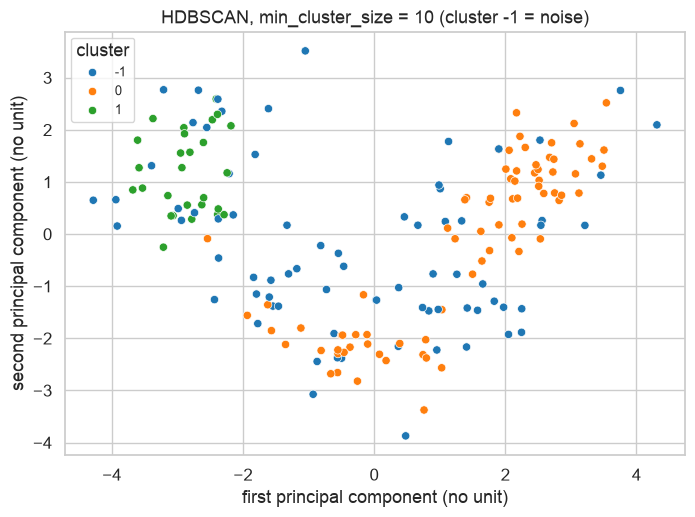

In [31]:
from sklearn.cluster import HDBSCAN

# min_cluster_size=10: report only groups of at least 10 wines; copy=True leaves the input data unchanged
hdbscan_pipeline = Pipeline([("scaling", StandardScaler()), ("hdbscan", HDBSCAN(min_cluster_size=10, copy=True))])
hdbscan_cluster = hdbscan_pipeline.fit_predict(wines)
is_noise = hdbscan_cluster == -1
print("clusters:", len(set(hdbscan_cluster[~is_noise])), "; noise wines:", is_noise.sum(), "of", len(wines))
print("ARI with variety (noise counted as one group):", round(adjusted_rand_score(cultivar, hdbscan_cluster), 3))

# The HDBSCAN clusters on the 2D map, the same one-line map as in 6.1; noise wines have the number -1
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(x=wines_pca_2d[:, 0], y=wines_pca_2d[:, 1], hue=hdbscan_cluster, palette="tab10", ax=ax)
ax.set_title("HDBSCAN, min_cluster_size = 10 (cluster -1 = noise)")
ax.set_xlabel("first principal component (no unit)")
ax.set_ylabel("second principal component (no unit)")
ax.legend(title="cluster", fontsize=9)
plt.show()

**What do you see?** HDBSCAN finds only two dense groups and calls 75 of the 178 wines noise. On the map, its cluster 0 joins the bottom and the upper right cloud, and the noise wines lie between and around the clouds. So its ARI with the varieties is low (0.263). With 178 wines in 13 dimensions the data are thin, and few regions are dense enough. HDBSCAN suits large data with dense groups of any shape and real outliers; for small data like these, k-means gives the more useful groups. A smaller `min_cluster_size`, or clustering on a few principal components, changes the result.